# 멀티모달 RAG 실습

PDF에서 **텍스트 · 표 · 이미지**를 추출하고, 각 요소를 요약해 다중 벡터 검색기로 색인한 뒤 질의하는 전체 파이프라인을 실행합니다.

**흐름:** `extract` → `summarize` → `retriever(index)` → `query` → `RAG 답변`

> 실행 전: 루트의 `.env.example` 을 `.env` 로 복사하고 `OPENAI_API_KEY` 를 채우세요.

In [10]:
# 0. 환경 설정
import sys
from pathlib import Path

# 프로젝트 루트를 import 경로에 추가 (src 패키지 사용)
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

from dotenv import load_dotenv
load_dotenv(ROOT / ".env")
print("ROOT =", ROOT)

ROOT = c:\workspaces\multimodal-rag2


In [1]:
import shutil
import sys

print("Python:", sys.version.split()[0])
print("가상환경 경로:", sys.prefix)
print("가상환경 안에서 실행 중?", ".venv" in sys.prefix)
print()

# OS 패키지 확인 (pip로 설치되지 않는 것들)
print("Poppler  :", "OK" if shutil.which("pdftoppm") else "✗ 미설치 — Path 확인 후 재시작")
print("Tesseract:", "OK" if shutil.which("tesseract") else "✗ 미설치 — Path 확인 후 재시작")
print()

# 파이썬 패키지 확인
for mod in ["langchain", "unstructured", "chromadb", "tiktoken", "PIL"]:
    try:
        __import__(mod)
        print(f"{mod:14s}: OK")
    except ImportError:
        print(f"{mod:14s}: ✗ 미설치")

Python: 3.11.9
가상환경 경로: c:\workspaces\multimodal-rag2\.venv
가상환경 안에서 실행 중? True

Poppler  : OK
Tesseract: OK

langchain     : OK
unstructured  : OK
chromadb      : OK
tiktoken      : OK
PIL           : OK


In [2]:
%pip install unstructured-inference


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os
import time
import pickle
from pathlib import Path

from langchain_text_splitters import CharacterTextSplitter
from unstructured.partition.pdf import partition_pdf

print("임포트 완료")

임포트 완료


In [4]:
# 노트북은 notebooks/ 안에서 실행되므로, 프로젝트 루트는 그 부모 폴더
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# TODO 1: 본인의 PDF 파일 이름으로 바꾸세요.
fname = "economy2024.pdf"

pdf_dir = PROJECT_ROOT / "data"          # 원본 PDF 폴더
pdf_path = pdf_dir / fname
fpath = str(pdf_dir) + os.sep            # 추출 함수에 path + fname 으로 넘기기 위함

# 추출된 이미지는 항상 <프로젝트 루트>/data/figures 에 저장
figures_dir = PROJECT_ROOT / "data" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

print("현재 위치     :", Path.cwd())
print("프로젝트 루트  :", PROJECT_ROOT)
print("PDF 경로      :", pdf_path.resolve())
print("PDF 존재 여부  :", pdf_path.exists())
print("이미지 저장폴더:", figures_dir.resolve())

현재 위치     : c:\workspaces\multimodal-rag2\notebooks
프로젝트 루트  : c:\workspaces\multimodal-rag2
PDF 경로      : C:\workspaces\multimodal-rag2\data\economy2024.pdf
PDF 존재 여부  : True
이미지 저장폴더: C:\workspaces\multimodal-rag2\data\figures


In [5]:
def extract_pdf_elements(path, fname):
    """
    PDF 파일에서 이미지, 테이블, 텍스트 블록을 추출합니다.

    path : 파일 경로 (추출된 이미지 파일이 저장될 위치)
    fname: 파일 이름
    """
    # 추출 이미지는 <프로젝트 루트>/data/figures 에 저장
    figures_dir = PROJECT_ROOT / "data" / "figures"
    figures_dir.mkdir(parents=True, exist_ok=True)

    return partition_pdf(
        filename=path + fname,
        strategy="hi_res",
        extract_images_in_pdf=True,
        infer_table_structure=True,
        chunking_strategy="by_title",
        max_characters=4000,
        new_after_n_chars=3800,
        combine_text_under_n_chars=2000,
        extract_image_block_output_dir=str(figures_dir),
    )

print("extract_pdf_elements 정의 완료")

extract_pdf_elements 정의 완료


In [6]:
def categorize_elements(raw_pdf_elements):
    """
    PDF에서 추출한 요소들을 테이블과 텍스트로 분류합니다.

    raw_pdf_elements: unstructured.documents.elements 리스트
    """

    tables = []
    texts = []

    for element in raw_pdf_elements:
        if "unstructured.documents.elements.Table" in str(type(element)):
            tables.append(str(element))       # TODO 5: 표는 tables 리스트
        elif "unstructured.documents.elements.CompositeElement" in str(type(element)):
            texts.append(str(element))        # TODO 6: 텍스트는 texts 리스트

    return texts, tables


print("categorize_elements 정의 완료")

categorize_elements 정의 완료


In [7]:
start = time.time()

raw_pdf_elements = extract_pdf_elements(fpath, fname)

print(f"추출 완료 — {time.time() - start:.1f}초 소요")
print("추출된 전체 요소 수:", len(raw_pdf_elements))

Thank you for using Unstructured Open Source! Try Unstructured's commercial offering for improved output quality. 10,000 free pages to start. Learn more: https://transform.unstructured.io/?utm_source=unstructured_oss Hide this notice: UNSTRUCTURED_DISABLE_NOTICE=1
No languages specified, defaulting to English.
Loading weights: 100%|██████████| 367/367 [00:00<00:00, 2787.91it/s]


추출 완료 — 164.9초 소요
추출된 전체 요소 수: 21


In [12]:
texts, tables = categorize_elements(raw_pdf_elements)

print("텍스트 블록 수:", len(texts))
print("표 블록 수    :", len(tables))

텍스트 블록 수: 15
표 블록 수    : 6


In [15]:
from collections import Counter

type_counts = Counter(str(type(el)).split(".")[-1].strip("'>") for el in raw_pdf_elements)

for element_type, count in type_counts.most_common():
    print(f"{element_type:22s}: {count}개")

CompositeElement      : 15개
Table                 : 6개


**TODO 7 답을 여기에 적으세요 (더블클릭해서 편집)**

- 가장 많이 나온 요소 타입:CompositeElement와 15개
- Table이 잡혔는가?:잡혔다. 총 6개의 Table 요소가 추출되었다.
- 그 이유는: strategy="hi_res"를 사용하여 PDF의 레이아웃을 분석하고 표 영역을 인식했으며, infer_table_structure=True 설정을 통해 표 구조를 추론했기 때문이다.

In [16]:
figures_dir = PROJECT_ROOT / "data" / "figures"

if figures_dir.exists():
    image_files = sorted(
        f for f in figures_dir.iterdir()
        if f.suffix.lower() in (".jpg", ".jpeg", ".png")
    )

    print(f"추출된 이미지: {len(image_files)}개\n")

    for f in image_files[:10]:
        print(f"  {f.name}  ({f.stat().st_size // 1024} KB)")
else:
    print("figures 폴더가 없습니다.")

추출된 이미지: 83개

  figure-1-1.jpg  (97 KB)
  figure-10-12.jpg  (44 KB)
  figure-10-13.jpg  (37 KB)
  figure-10-14.jpg  (6 KB)
  figure-12-15.jpg  (43 KB)
  figure-12-16.jpg  (43 KB)
  figure-12-17.jpg  (6 KB)
  figure-13-18.jpg  (42 KB)
  figure-14-19.jpg  (44 KB)
  figure-15-20.jpg  (47 KB)


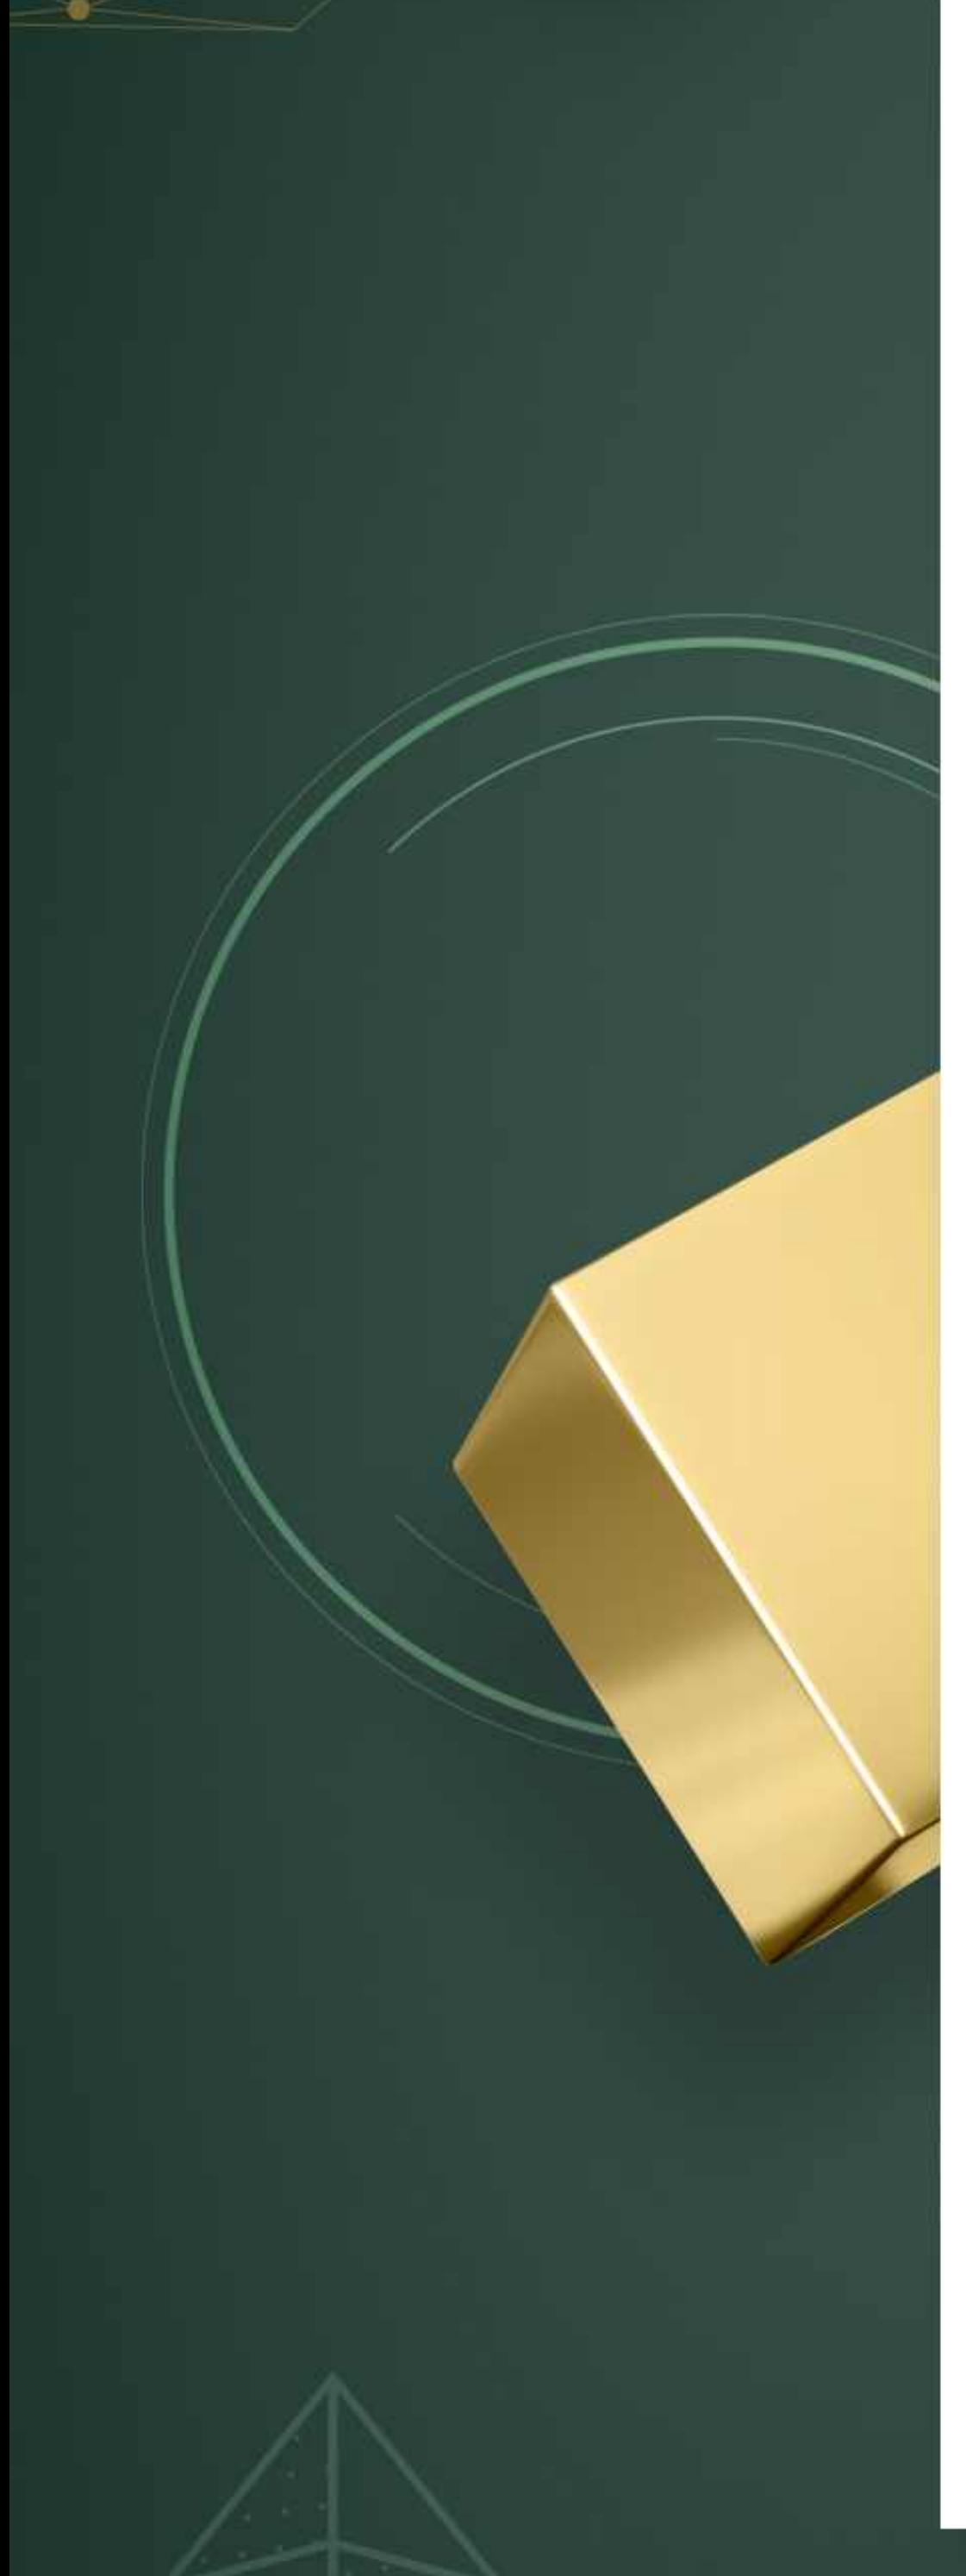

In [17]:
# 첫 번째 이미지를 노트북에서 직접 확인
from IPython.display import Image, display

if figures_dir.exists() and image_files:
    display(Image(filename=str(image_files[0]), width=500))
else:
    print("표시할 이미지가 없습니다.")

In [18]:
text_splitter = CharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=2000,       # 각 텍스트 블록의 최대 크기
    chunk_overlap=200,    # TODO 8: 청크 간 겹칠 글자 수
)

joined_texts = " ".join(texts)
texts_2k_token = text_splitter.split_text(joined_texts)

print("원본 블록 수  :", len(texts))
print("분할 후 블록 수:", len(texts_2k_token))
print("전체 글자 수  :", len(joined_texts))

원본 블록 수  : 15
분할 후 블록 수: 34
전체 글자 수  : 33890


In [19]:
print("=" * 60)
print("[원본 texts[0]] 앞 300자")
print("=" * 60)
print(texts[0][:300])
print()

print("=" * 60)
print("[분할 texts_2k_token[0]] 앞 300자")
print("=" * 60)
print(texts_2k_token[0][:300])


[원본 texts[0]] 앞 300자
24-09(통권 967호) 2024.06.05

oM=S

2024년 한국 경제 전망(수정) - 2024년 경제성장률, 0.5%p 상향조정한 2.7%

목 차

v

■ 2024년 한국 경제 전망(수정) - 2024년 경제성장률, 0.5%p 상향조정한 2.7% Executive Summary ······················································································ⅰ 1. 대외 경제 환경 변화 ·································

[분할 texts_2k_token[0]] 앞 300자
24-09(통권 967호) 2024.06.05

oM=S

2024년 한국 경제 전망(수정) - 2024년 경제성장률, 0.5%p 상향조정한 2.7%

목 차

v

■ 2024년 한국 경제 전망(수정) - 2024년 경제성장률, 0.5%p 상향조정한 2.7% Executive Summary ······················································································ⅰ 1. 대외 경제 환경 변화 ·································


In [20]:
output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

with open(output_dir / "extracted.pkl", "wb") as f:
    pickle.dump(
        {"texts": texts, "tables": tables, "texts_2k_token": texts_2k_token},
        f,
    )

print("저장 완료:", output_dir / "extracted.pkl")

저장 완료: c:\workspaces\multimodal-rag2\data\processed\extracted.pkl


In [21]:
# ⌨️ 0-1. os, time, pickle, Path(pathlib), load_dotenv(dotenv) 를 임포트합니다.
import os
import time
import pickle
from pathlib import Path
from dotenv import load_dotenv

# ⌨️ 0-2. PROJECT_ROOT 를 정합니다.
#        노트북은 notebooks/ 안에서 실행되므로, 그 부모 폴더가 프로젝트 루트
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
# ⌨️ 0-3. PROJECT_ROOT / ".env" 파일을 load_dotenv 로 읽습니다.
load_dotenv(PROJECT_ROOT / ".env")
# ⌨️ 0-4. 환경변수 "OPENAI_API_KEY" 를 openai_api_key 에 담습니다.
openai_api_key = os.getenv("OPENAI_API_KEY")
# ⌨️ 0-5. 키가 없으면 ValueError 를 발생시킵니다.
if not openai_api_key:
    raise ValueError("OPENAI_API_KEY 환경변수가 설정되지 않았습니다.")
# ⌨️ 0-6. 키를 "앞 7자 + ... + 뒤 4자" 형태로만 출력합니다.
print("프로젝트 루트:", PROJECT_ROOT)
print(f"OPENAI_API_KEY: {openai_api_key[:7]}...{openai_api_key[-4:]}")

프로젝트 루트: c:\workspaces\multimodal-rag2
OPENAI_API_KEY: sk-proj...Vq0A


In [22]:
# ⌨️ 0-7. 키가 실제로 유효한지 확인합니다.
from openai import OpenAI, AuthenticationError
try:
    OpenAI(api_key=openai_api_key).models.list()
    print("OPENAI_API_KEY가 유효합니다.")
except AuthenticationError:
    print("OPENAI_API_KEY가 유효하지 않습니다. 환경변수를 확인하세요.")

    
#        openai 패키지에서 OpenAI, AuthenticationError 를 임포트하고
#        OpenAI().models.list() 를 호출해 AuthenticationError 가 나면 안내 문구와 함께 중단합니다.



OPENAI_API_KEY가 유효합니다.


In [23]:
# ⌨️ 1-1. PROJECT_ROOT / "data" / "processed" / "extracted.pkl" 경로를 pkl_path 에 담습니다.
pkl_path = PROJECT_ROOT / "data"/ "processed" / "extracted.pkl"
# ⌨️ 1-2. 파일을 바이너리 읽기 모드("rb")로 열어 pickle.load 로 data 에 불러옵니다.
with open(pkl_path, "rb") as f:
    data = pickle.load(f)
# ⌨️ 1-3. data 딕셔너리에서 texts, tables, texts_2k_token 을 꺼냅니다.
texts = data["texts"]
tables = data["tables"]
texts_2k_token = data["texts_2k_token"]

# ⌨️ 1-4. 각 리스트의 개수를 출력합니다.
print(f"텍스트 개수: {len(texts)}")
print(f"표 개수: {len(tables)}")
print(f"2k 토큰 텍스트 개수: {len(texts_2k_token)}")

# ⌨️ 1-5. 지난 시간에 이미지를 저장한 폴더를 figures_dir 로 잡고 존재 여부를 출력합니다.
#        (지난 시간: PDF 폴더 아래 "figures" → PROJECT_ROOT / "data" / "figures")
figures_dir= PROJECT_ROOT / "data" / "figures"
print(f"figures_dir 존재 여부: {figures_dir.exists()}")


텍스트 개수: 15
표 개수: 6
2k 토큰 텍스트 개수: 34
figures_dir 존재 여부: True


In [24]:
# ⌨️ 2-1. StrOutputParser, ChatPromptTemplate, ChatOpenAI 를 임포트합니다.
#        (langchain_core.output_parsers / langchain_core.prompts / langchain_openai)
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI

# ⌨️ 2-2. generate_text_summaries(texts, tables, summarize_texts=False) 함수를 정의합니다.
def generate_text_summaries(texts, tables, summarize_texts=False):

    #   ⌨️ (1) 한국어 요약 프롬프트 문자열을 작성합니다. 반드시 {element} 자리표시자를 포함합니다.
    prompt_text_kor = """표와 텍스트를 검색용으로 요약하는 도우미 / 임베딩되어 원본 검색에 쓰임 /
검색에 최적화된 간결한 요약 작성 / 요약할 표 또는 텍스트: {element}"""

    #   ⌨️ (2) ChatPromptTemplate.from_template 으로 prompt 를 만듭니다.
    prompt = ChatPromptTemplate.from_template(prompt_text_kor)

    #   ⌨️ (3) ChatOpenAI 로 model 을 만듭니다. (temperature=0, model="gpt-4o-mini")
    model = ChatOpenAI(temperature=0, model="gpt-4o-mini")

    #   ⌨️ (4) 컨베이어 벨트 4칸을 | 로 연결해 summarize_chain 을 만듭니다.
    #   요약을 위한 체인 = 입력포장 | 프롬프트 | 모델 | 출력파서
    summarize_chain =  prompt | model | StrOutputParser()

    #   ⌨️ (5) text_summaries, table_summaries 빈 리스트를 만듭니다.
    text_summaries = []
    table_summaries = []

    #   ⌨️ (6) texts 가 있고 summarize_texts 가 True 면 → batch 로 요약 (max_concurrency 5)
    #          texts 는 있지만 summarize_texts 가 False 면 → 원문을 그대로 사용
    if texts and summarize_texts:
        text_summaries = summarize_chain.batch(texts, config={"max_concurrency": 5})
    elif texts:
        text_summaries = texts

    #   ⌨️ (7) tables 가 있으면 → batch 로 요약 (max_concurrency 5)
    if tables:
        table_summaries = summarize_chain.batch(tables, config={"max_concurrency": 5})

    return text_summaries, table_summaries

# ⌨️ 2-3. "generate_text_summaries 정의 완료" 를 출력합니다.
print("generate_text_summaries 정의 완료")


generate_text_summaries 정의 완료


In [25]:
# ⌨️ 3-1. 시작 시각을 기록합니다.
start = time.time()
# ⌨️ 3-2. texts_2k_token 과 tables 를 넣어 generate_text_summaries 를 호출합니다.
#        텍스트도 요약해야 하므로 summarize_texts=True
text_summaries, table_summaries = generate_text_summaries(texts_2k_token, tables, summarize_texts=True)

# ⌨️ 3-3. 소요 시간, 텍스트 요약 수, 표 요약 수를 출력합니다.
print(f"소요 시간: {time.time() - start:.2f}초")
print(f"텍스트 요약 수: {len(text_summaries)}")
print(f"표 요약 수: {len(table_summaries)}")
print("요약 생성 완료")


소요 시간: 63.04초
텍스트 요약 수: 34
표 요약 수: 6
요약 생성 완료


In [26]:
# ⌨️ 4-1. 구분선과 함께 texts_2k_token[0] 의 앞 300자를 출력합니다.
print("-"*60)
print("[원본]texts_2k_token[0][:300] -  앞 300자")
print("-"*60)
print(texts_2k_token[0][:300])
print()
# ⌨️ 4-2. 구분선과 함께 text_summaries[0] 전체를 출력합니다.
print("-"*60)
print("[원본]text_summaries[0]")
print("-"*60)
print(text_summaries[0])
print()
# ⌨️ 4-3. 원본 글자 수, 요약 글자 수, 압축률(%)을 출력합니다.
origin = len(texts_2k_token[0])
summ = len(text_summaries[0])
print(f"압축률: {origin}자 ({summ/origin * 100:.2f}%)")



------------------------------------------------------------
[원본]texts_2k_token[0][:300] -  앞 300자
------------------------------------------------------------
24-09(통권 967호) 2024.06.05

oM=S

2024년 한국 경제 전망(수정) - 2024년 경제성장률, 0.5%p 상향조정한 2.7%

목 차

v

■ 2024년 한국 경제 전망(수정) - 2024년 경제성장률, 0.5%p 상향조정한 2.7% Executive Summary ······················································································ⅰ 1. 대외 경제 환경 변화 ·································

------------------------------------------------------------
[원본]text_summaries[0]
------------------------------------------------------------
**2024년 한국 경제 전망 요약**

- **경제성장률**: 2024년 한국 경제성장률이 2.2%에서 2.7%로 0.5%p 상향 조정됨.
- **배경**: 
  - 1분기 경제성장률이 예상보다 양호함.
  - 수출 경기 회복이 견조하나 내수 부진으로 수입이 감소, 무역·경상수지 흑자 구조 강화.
- **경기 신호**: 4월 동행지수 순환변동치 하락으로 경기 회복 신호 미비, 완전한 회복 판단은 이르다고 평가.

**문의처**: 
- 주 원 경제연구실장 (02-2072-6235, juwon@hri.co.kr)
- 이부형 동향분석팀장 (2072-6306, leebuh@hri.co.kr)
- 신지영 선임연구원 (2072-6240, jyshin@hri.co.kr)
- 노시연 선임연구원 (2072-62

In [27]:
# ⌨️ 5-1. table_summaries 가 있으면 → 개수와 첫 번째 표 요약을 출력합니다.

# ⌨️ 5-2. 비어 있으면 → 위 두 가지 원인을 점검하라는 안내 문구를 출력합니다.

# ⌨️ 5-1. table_summaries 가 있으면 → 개수와 첫 번째 표 요약을 출력합니다.

# ⌨️ 5-2. 비어 있으면 → 위 두 가지 원인을 점검하라는 안내 문구를 출력합니다.
if table_summaries:
    # print(f"표 요약 => {len(table_summaries)} 건 생성됨 \n")
    # print("[표 요약 예시]")
    # print(table_summaries[0])

    # for i , summary in enumerate(table_summaries[:3]):
    #     print("="*60)
    #     print(f"[표 요약 {i+1}]")
    #     print("="*60)
    #     print(summary)
    #     print()

    #원본 표와 함께 비교하고 싶다. zip(tables, table_summaries) 두리스트에서 같은 순번끼리
    #하나씩 꺼낸다.  요약은 원본 순서대로 만들어 졌으므로 [0] [0]끼리, [1] [1] 짝을 맞춰서
    for i, (table,summary) in enumerate(zip(tables[:2], table_summaries[:2])):
            print("="*60)
            print(f"[표 {i+1} 원본 (앞 300자)]")
            print("="*60)
            print(table[:300])
            print()
            print("="*60)
            print(f"[표 {i+1} 요약 ]")
            print("="*60)
            print(summary)
            print()
else:
    print("표 요약이 비어 있습니다. " \
    "     원인은 1. strategy = 'hi_res' 2. 진짜 표인지, 그림으로 그린 표인지 확인")

[표 1 원본 (앞 300자)]
구 분 2022 2023 2024(E) 상반 하반 연간 상반 하반 연간 국 경제성장률 (%) 2.7 1.0 1.7 1.4 2.8 2.6 2.7 민 민간소비 (%) 4.2 3.1 0.5 1.8 1.2 2.1 1.7 계 건설투자 (%) △3.5 1.7 1.4 1.5 △0.5 0.7 0.1 정 설비투자 (%) △0.3 4.2 △2.0 1.1 1.0 6.7 3.8 대 경상수지 (억 달러) 258 11 343 355 310 300 610 외 무역수지 (억 달러) △478 △263 159 △103 226 208 434 거 수출증가율 (%) 6

[표 1 요약 ]
### 요약

- **국 경제성장률**: 2022년 2.7%, 2023년 1.0%, 2024년(E) 1.7%
- **민간소비**: 2022년 4.2%, 2023년 3.1%, 2024년(E) 1.8%
- **건설투자**: 2022년 -3.5%, 2023년 1.7%, 2024년(E) 1.5%
- **설비투자**: 2022년 -0.3%, 2023년 4.2%, 2024년(E) 1.1%
- **경상수지**: 2022년 258억 달러, 2023년 11억 달러, 2024년(E) 343억 달러
- **무역수지**: 2022년 -478억 달러, 2023년 -263억 달러, 2024년(E) 159억 달러
- **수출증가율**: 2022년 6.1%, 2023년 -12.4%, 2024년(E) -2.4%
- **수입증가율**: 2022년 18.9%, 2023년 -7.8%, 2024년(E) -16.4%
- **소비자물가상승률**: 2022년 5.1%, 2023년 3.9%, 2024년(E) 3.6%
- **실업률**: 2022년 2.9%, 2023년 3.0%, 2024년(E) 2.5%
- **취업자수 증감**: 2022년 82만 명 증가, 2023년 37만 명 증가, 2024년(E) 28만 명 증가

이 데이터는 한국 경제의 성장률, 소비, 투자, 무역, 물가, 실업률 등을 요약하여 보여줍니다.

[표 2 

In [28]:
# ⌨️ 6-1. base64 모듈과 HumanMessage(langchain_core.messages)를 임포트합니다.
import base64
from langchain_core.messages import HumanMessage

# ⌨️ 6-2. encode_image(image_path) 함수를 정의합니다.
#        파일을 "rb" 로 열어 → b64encode → "utf-8" 로 decode 한 문자열을 반환
def encode_image(image_path):
    with open(image_path , "rb") as image_file:
        return base64.b64encode(image_file.read()).decode("utf-8")
# ⌨️ 6-3. figures_dir 에서 .jpg / .jpeg / .png 파일만 골라 정렬해 image_files 에 담습니다.

# ⌨️ 6-4. 첫 번째 이미지를 인코딩해 sample_b64 에 담고 파일 이름, 문자열 길이, 앞 100자를 출력합니다.
image_files = sorted( # 3. 이름순으로 정렬해서 리스트로 반환하겠다.
    f for f in figures_dir.iterdir() # 1. 폴더안의 항목들을 하나씩 꺼내
     if f.suffix.lower() in (".jpg", ".jpeg", ".png")) #2. 확장자가 이미지인 것만 

sample_b64 = encode_image(image_files[0])

print("원본파일 =>" , image_files[0].name)
print("문자열 길이 =>", len(sample_b64), "자")
print("앞 100자: ", sample_b64[:100])



원본파일 => figure-1-1.jpg
문자열 길이 => 132616 자
앞 100자:  /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAx


In [39]:
# ⌨️ 7-1. image_summarize(img_base64, prompt) 함수를 정의합니다.
def image_summarize(img_base64, prompt):
    #   ⌨️ (1) ChatOpenAI 로 chat 을 만듭니다. (model="gpt-4o-mini", max_tokens=1024)
    chat = ChatOpenAI(model="gpt-4o-mini", max_tokens=1024)
    #   ⌨️ (2) 위 구조대로 HumanMessage 를 만들어 chat.invoke([...]) 로 호출합니다.
    #          이미지 url 은 "data:image/jpeg;base64," 접두사 뒤에 img_base64 를 붙입니다.
    msg = chat.invoke([
        HumanMessage(
            content=[
                {"type": "text", "text": prompt},
                {"type": "image_url", "image_url": {"url": f"data:image/jpeg;base64,{img_base64}"}}
            ]
        )
    ])
    #   ⌨️ (3) 응답의 .content 를 반환합니다.
    return msg.content


# ⌨️ 7-2. 테스트용 영어 프롬프트 test_prompt 를 작성합니다.
#        내용: 검색용 이미지 요약 도우미 / 요약은 임베딩되어 원본 이미지 검색에 쓰임 /
#              검색에 최적화된 간결한 요약 / 마지막 줄에 "한국어(Hangul)로 작성" 지시
test_prompt = """You are an assistant tasked with summarizing images for retrieval.
These summaries will be embedded and used to retrieve the raw image.
Provide a concise summary of the image that is well optimized for retrieval.
The summary should be written in Korean (Hangul)."""

# ⌨️ 7-3. sample_b64 와 test_prompt 로 image_summarize 를 호출해 결과를 출력합니다.
print(image_summarize(sample_b64, test_prompt))


녹색 배경 위에 금색 사각형이 비스듬히 놓여 있는 이미지. 배경에는 원과 기하학적 도형의 윤곽이 담겨 있음.


In [35]:
# ⌨️ 8-1. generate_img_summaries(path) 함수를 정의합니다.
def generate_img_summaries(path):
    """
    이미지의 요약과 Base64 인코딩 문자열을 생성
    path: Unstructured에 의해 추출된 .jpg 파일의 경로
    """
    #   ⌨️ (1) img_base64_list, image_summaries 빈 리스트를 만듭니다.
    img_base64_list = []   # Base64로 인코딩된 이미지를 저장할 리스트
    image_summaries = []   # 이미지 요약을 저장할 리스트

    #   ⌨️ (2) 7번과 같은 검색용 이미지 요약 프롬프트(prompt_kor)를 작성합니다.
    prompt_kor = """You are an assistant tasked with summarizing images for retrieval.
These summaries will be embedded and used to retrieve the raw image.
Provide a concise summary of the image that is well optimized for retrieval.
The summary should be written in Korean (Hangul)."""

    #   ⌨️ (3) os.listdir(path) 를 정렬해 반복하면서
    #          확장자가 (".jpg", ".jpeg", ".png") 인 파일만
    #          → 전체 경로 만들기 → encode_image → 리스트에 추가
    #          → image_summarize 결과를 요약 리스트에 추가
    for img_file in sorted(os.listdir(path)):
        if img_file.lower().endswith((".jpg", ".jpeg", ".png")):
            img_path = os.path.join(path, img_file)
            base64_image = encode_image(img_path)
            img_base64_list.append(base64_image)
            image_summaries.append(image_summarize(base64_image, prompt_kor))

    #   ⌨️ (4) img_base64_list, image_summaries 를 반환합니다.
    return img_base64_list, image_summaries


# ⌨️ 8-2. 시간을 재면서 str(figures_dir) 로 함수를 호출하고, 소요 시간과 요약된 이미지 수를 출력합니다.
start = time.time()
img_base64_list, image_summaries = generate_img_summaries(str(figures_dir))
print(f"소요 시간: {time.time() - start:.2f}초")
print(f"요약된 이미지 수: {len(image_summaries)}")


소요 시간: 161.14초
요약된 이미지 수: 83


[0] figure-1-1.jpg


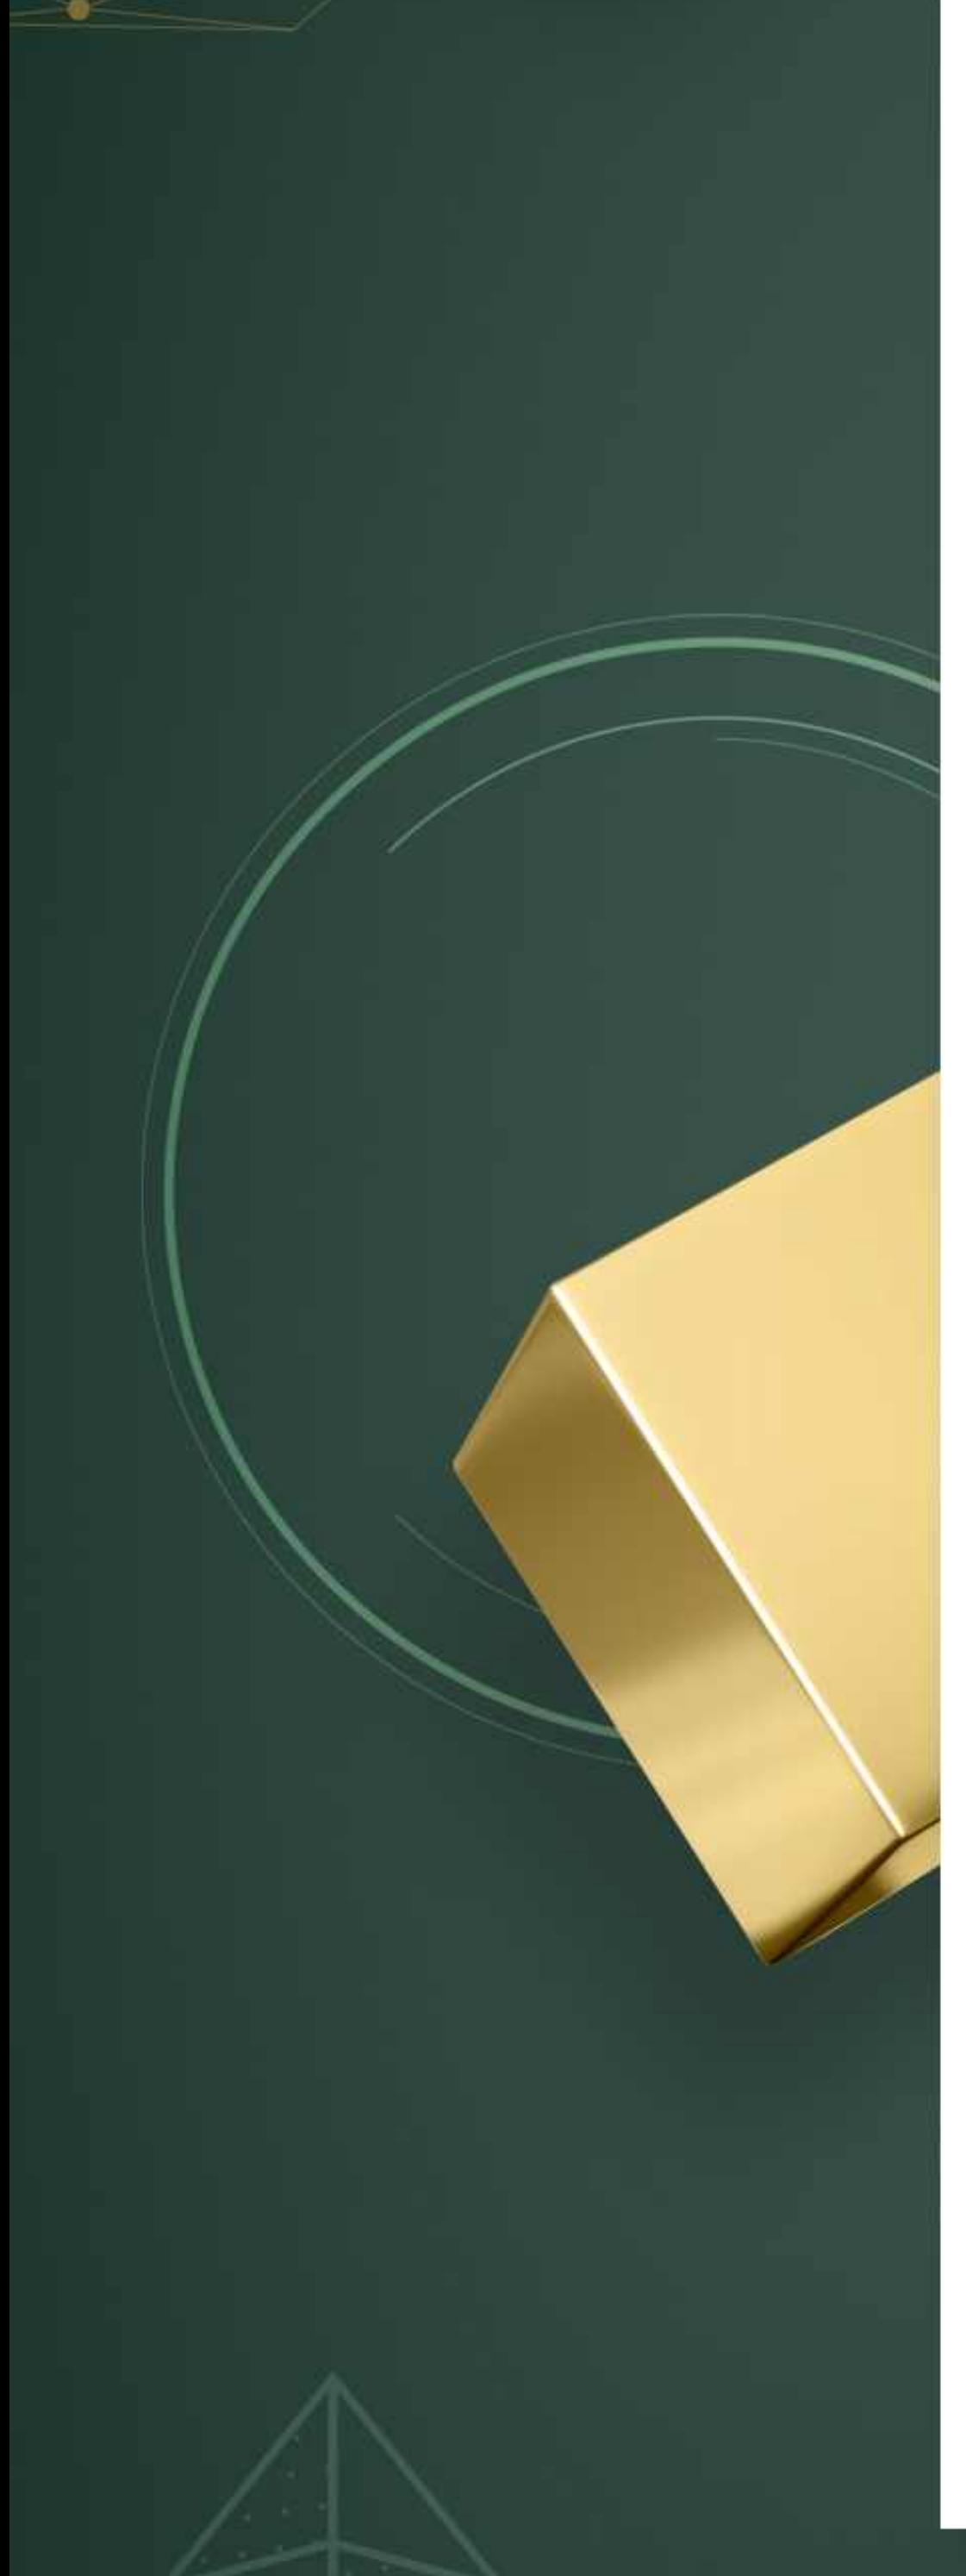

요약: 검은색 배경에 금색 각진 형태의 물체가 부분적으로 보이는 이미지. 디자인 요소로 원형과 기하학적 패턴이 포함되어 있음.

[1] figure-10-12.jpg


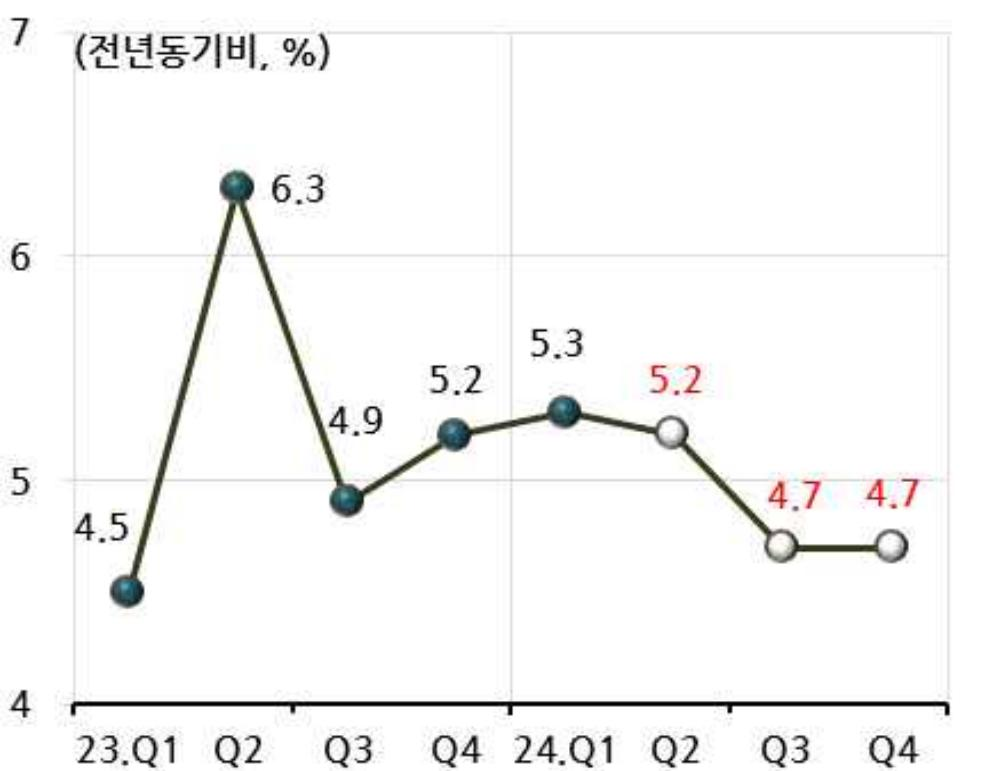

요약: 전년동기비(%) 변동 그래프. 2023년 1분기 4.5%에서 시작해 2분기에 6.3%로 증가, 이후 3분기 4.9%, 4분기 5.2% 변동. 2024년에는 5.3%, 5.2%, 4.7%로 감소함.



In [36]:
# ⌨️ 9-1. IPython.display 에서 Image, display 를 임포트합니다.
from IPython.display import Image, display
for i, (img_file, summary) in enumerate(zip(image_files[:2], image_summaries[:2])):
    print("="*60)
    print(f"[{i}] {img_file.name}")
    print("="*60)
    display(Image(filename=str(img_file), width=450))
    print("요약:", summary)
    print()
# ⌨️ 9-2. image_files 와 image_summaries 의 앞 3개를 zip + enumerate 로 반복하며
#        구분선, 번호와 파일 이름, 이미지(width=450), 요약문을 차례로 출력합니다.



In [37]:
# ⌨️ 10-1. tiktoken 을 임포트하고 "gpt-4o-mini" 용 인코더(enc)를 가져옵니다.

# ⌨️ 10-2. texts_2k_token 전체의 토큰 수 합 → input_tokens

# ⌨️ 10-3. text_summaries 전체의 토큰 수 합 → output_tokens

# ⌨️ 10-4. 입력 / 출력 / 합계 토큰(천 단위 콤마)과 요약한 이미지 수를 출력합니다.
import tiktoken

enc = tiktoken.encoding_for_model("gpt-4o-mini")

input_tokens = sum(len(enc.encode(t)) for t in texts_2k_token)
output_tokens = sum(len(enc.encode(s)) for s in text_summaries)

print("텍스트 요약 토큰 사용량 (추정)")
print(f"  입력 : {input_tokens:,} 토큰")
print(f"  출력 : {output_tokens:,} 토큰")
print(f"  합계 : {input_tokens + output_tokens:,} 토큰")
print()
print("요약한 이미지 수:", len(image_summaries), "장")
print()
print("※ 실제 비용 = 토큰 수 x 단가. 단가는 OpenAI 공식 가격 페이지에서 확인하세요.")
print("※ 이미지 토큰은 해상도에 따라 달라지므로 위 수치에 포함되지 않았습니다.")


텍스트 요약 토큰 사용량 (추정)
  입력 : 22,207 토큰
  출력 : 10,473 토큰
  합계 : 32,680 토큰

요약한 이미지 수: 83 장

※ 실제 비용 = 토큰 수 x 단가. 단가는 OpenAI 공식 가격 페이지에서 확인하세요.
※ 이미지 토큰은 해상도에 따라 달라지므로 위 수치에 포함되지 않았습니다.


In [38]:
# ⌨️ 11-1. PROJECT_ROOT / "data" / "processed" 를 output_dir 로 잡고 폴더를 만듭니다. (parents, exist_ok)

# ⌨️ 11-2. output_dir / "summaries.pkl" 에 아래 4개 키를 가진 딕셔너리를 pickle.dump 합니다.
#         text_summaries, table_summaries, image_summaries, img_base64_list

# ⌨️ 11-3. 저장 경로를 출력합니다.
output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

with open(output_dir / "summaries.pkl", "wb") as f:
    pickle.dump(
        {
            "text_summaries": text_summaries,
            "table_summaries": table_summaries,
            "image_summaries": image_summaries,
            "img_base64_list": img_base64_list,
        },
        f,
    )

print("저장 완료:", output_dir / "summaries.pkl")
print("7교시에서 extracted.pkl 과 summaries.pkl 을 함께 불러옵니다.")



저장 완료: c:\workspaces\multimodal-rag2\data\processed\summaries.pkl
7교시에서 extracted.pkl 과 summaries.pkl 을 함께 불러옵니다.


---

## ✅ 오늘의 체크포인트

- [ ] `text_summaries[0]`에 한국어 요약문이 출력된다
- [ ] `image_summaries[0]`에 그림을 설명하는 한국어 문장이 출력된다
- [ ] 그림과 요약문을 나란히 놓고 **육안으로 검증**했다
- [ ] `table_summaries`가 비어도 그 이유를 설명할 수 있다
- [ ] `data/processed/summaries.pkl` 파일이 생성되었다

## 💬 생각해 볼 질문 (더블클릭해서 편집)

**Q1. 이미지를 왜 굳이 텍스트로 요약할까요? 이미지 그대로 검색하면 안 되나요?**

답: 텍스트 RAG의경우 이미지를 읽어올 수 없고 정확한 이미지를 읽지 못하기때문

**Q2. 요약문만 저장하고 원본은 버리면 어떤 문제가 생길까요?**

답: 정확한 근거를 답변으로 찾아서 내려줄 수 없다.

**Q3. `max_concurrency`를 100으로 올리면 어떤 일이 벌어질까요?**

답: 총 호출 수가 같으니 비용 총액은 변하지 않습니다. 다만 한 번에 폭발적으로 나가면 실수로 큰 배치를 돌렸을 때 제동 걸기 어렵습니다.

## 🛠️ 자주 나는 에러

| 증상 | 원인 | 해결 |
| --- | --- | --- |
| `AuthenticationError` | `.env` 키 오타 / `load_dotenv()` 누락 | 키 앞뒤 공백·따옴표 제거 |
| `404 model not found` | 지원 종료된 모델명 사용 | `gpt-4o-mini` 사용 |
| `RateLimitError` | 동시 요청 과다 | `max_concurrency`를 5 → 2로 낮추기 |
| `FileNotFoundError: extracted.pkl` | 지난 시간 저장 셀 미실행 | 지난 노트북 마지막 셀 재실행 |
| `IndexError: list index out of range` | `figures/`에 이미지가 없음 | 1번 셀의 `figures_dir` 경로 확인 |
| 요약이 영어로 나옴 | 프롬프트에 한국어 지시 누락 | 프롬프트 마지막 줄 확인 |
| `NameError` | 앞 셀을 안 돌림 | 위에서부터 순서대로 재실행 |

> 그래도 안 되면 **커널 재시작 후 위에서부터 전체 재실행**하세요.

## ⏭️ 다음 시간 예고
오늘 만든 요약문을 **임베딩해 벡터 저장소(Chroma)에 넣고**, 요약으로 검색해 **원본**을 돌려주는 **멀티 벡터 검색기**를 만듭니다.

In [40]:
# ── 0. 결과 복원 ──────────────────────────────────────────
# 1) 필요한 모듈 import: os, re, time, uuid, pickle, pathlib.Path
import os #운영체제 기능(환경변수, 파일, 폴더 다루기 위한 기능)
import re #정규표현식으로 문자열 패턴, 만든 검사, 검색, 치환
import time # 현재 시각 확인, 시간 측정, 대기 (체인 답변 생성 시간 측정)
import uuid # 겹치지 않는 고유 ID 생성 uuid. uuid4() 요약본, 원본을 doc_id로 페어링
import pickle # 파이썬 
from pathlib import Path 

# 2) python-dotenv 의 load_dotenv import
from dotenv import load_dotenv 
# 3) .env 가 있는 폴더를 프로젝트 루트로 자동 탐색
#    - Path.cwd() 와 그 상위 폴더(parents)를 차례로 확인해 (p / ".env") 가 존재하는 첫 경로를 PROJECT_ROOT 로 지정
#    - 찾지 못하면 Path.cwd() 를 사용
#    - PROJECT_ROOT 출력 → c:\workspaces\multimodal-rag 이면 정상
PROJECT_ROOT = next((p for p in[Path.cwd(), *Path.cwd().parents] if(p/".env").exists()), Path.cwd())
print("프로젝트 루투:", PROJECT_ROOT)
# 4) PROJECT_ROOT 의 .env 파일 로드 (load_dotenv)
load_dotenv(PROJECT_ROOT / ".env")
# 5) OPENAI_API_KEY 가 없으면 ValueError 발생시키기
try:
    openai_api_key = os.environ["OPENAI_API_KEY"]
    if not openai_api_key.strip():
        raise ValueError("OPEN_API_KEY 값이 비어 있습니다. .env파일 확인해 주세요")
except KeyError:
    raise ValueError()
# 6) processed 경로 = PROJECT_ROOT / "data" / "processed"
processed = PROJECT_ROOT / "data" /"Processed"
# 7) 추출 결과 복원: processed/"extracted.pkl" 을 pickle 로 읽기 ("rb")
#    - texts, tables, texts_2k_token 꺼내기
with open(processed/"extracted.pkl","rb") as f:
    doc1 = pickle.load(f)
    texts, tables, texts_2k_token = doc1["texts"], doc1["tables"],doc1["texts_2k_token"]
# 8) 요약 결과 복원: processed/"summaries.pkl" 을 pickle 로 읽기
#    - text_summaries, table_summaries, image_summaries, img_base64_list 꺼내기
with open(processed/"summaries.pkl","rb") as f1:
    doc2 = pickle.load(f1)
    text_summaries = doc2["text_summaries"]
    table_summaries = doc2["table_summaries"]
    image_summaries = doc2["image_summaries"]
    img_base64_list = doc2["img_base64_list"]
# 9) "복원 완료" 와 함께 텍스트·표·이미지의 원본 수 / 요약 수 출력
print("복원 완료")
print(f"텍스트 원본 {len(texts_2k_token):3d}건 / 요약{len(text_summaries):3d} 건")
print(f" 테이블 원본 {len(tables):3d}건  / 요약{len(table_summaries):3d} 건")
print(f" 이미지 원본 {len(img_base64_list):3d}건  / 요약{len(image_summaries):3d} 건")

프로젝트 루투: c:\workspaces\multimodal-rag2
복원 완료
텍스트 원본  34건 / 요약 34 건
 테이블 원본   6건  / 요약  6 건
 이미지 원본  83건  / 요약 83 건


In [41]:
# ── 2. 검색기 만들기 ──────────────────────────────────────
# langchain 1.x 에서 두 클래스의 위치가 바뀌었습니다.
# 어느 버전을 설치했든 동작하도록 두 경로를 모두 시도합니다. (try / except ImportError)

# 1) MultiVectorRetriever import
#    - langchain 1.x : langchain_classic.retrievers.multi_vector
#    - langchain 0.3 : langchain.retrievers.multi_vector
try:
    from langchain_classic.retrievers.multi_vector import MultiVectorRetriever
except ImportError:
    print("MultiVectorRetriever 클래스가 필요합니다.")

# 2) InMemoryStore import
#    - langchain 1.x : langchain_core.stores
#    - langchain 0.3 : langchain.storage
try:
    from langchain_core.stores import InMemoryStore
except:
    print("InMemoryStore 클래스가 필요합니다.")
# 3) Chroma(langchain_chroma), OpenAIEmbeddings(langchain_openai) import
from langchain_chroma import Chroma
from langchain_openai import OpenAIEmbeddings

# 4) 요약문이 들어갈 벡터 DB (= 색인 카드 서랍)
#    - collection_name="multimodal_rag"
#    - embedding_function = OpenAIEmbeddings(model="text-embedding-3-small")
vectorstore = Chroma( collection_name="multimodal_rag", embedding_function= OpenAIEmbeddings(model="text-embedding-3-small"))
# 5) 원본이 들어갈 저장소 (= 서가) : InMemoryStore()
store = InMemoryStore()
# 6) 연결 키(= 청구기호) : id_key = "doc_id"
id_key = "doc_Id"
# 7) MultiVectorRetriever(vectorstore=..., docstore=..., id_key=...) 생성
retriever = MultiVectorRetriever(
    vectorstore= vectorstore, docstore = store, id_key = id_key
)
# 8) "검색기 생성 완료" 출력
print("검색기 생성 완료")


검색기 생성 완료


In [42]:
# ── 3. 요약과 원본을 같은 ID로 짝짓기 ─────────────────────
# 1) langchain_core.documents 의 Document import
from langchain_core.documents import Document as _Doc

# 2) add_documents(retriever, doc_summaries, doc_contents) 함수 정의
#    """요약본은 벡터 DB에, 원본은 docstore에 '같은 id'로 저장합니다."""
#    - 원본 개수만큼 uuid4 로 doc_ids 생성 (문자열로 변환)
#    - 요약문마다 Document(page_content=요약, metadata={id_key: doc_ids[i]}) 생성
def add_documents(retriever, doc_summaries, doc_contents):
    doc_ids = []
    #for _ in doc_contents:
       #new_id = str(uuid.uuid4())
        #doc_ids.append(new_id)
    doc_ids = [str(uuid.uuid4()) for _ in doc_contents]

    summary_docs = [
        _Doc(page_content= s, metadata={id_key:doc_ids[i]})
        for i ,s in enumerate(doc_summaries) 
    ]
#    - TODO 1: 요약본은 어디에 넣을까요? (vectorstore / docstore)
#      → retriever.vectorstore.add_documents(...)
    retriever.vectorstore.add_documents(summary_docs)
#    - TODO 2: 원본은 어디에 넣을까요?
#      → retriever.docstore.mset(list(zip(doc_ids, doc_contents)))
    retriever.docstore.mset(list(zip(doc_ids, doc_contents)))

# 3) 데이터가 있을 때만 각각 저장
#    - text_summaries  ↔ texts_2k_token
#    - table_summaries ↔ tables
#    - image_summaries ↔ img_base64_list
if text_summaries:
    add_documents(retriever, text_summaries, texts_2k_token)
if table_summaries:
    add_documents(retriever, table_summaries, tables)
if image_summaries:
    add_documents(retriever, image_summaries, img_base64_list)

print("색인 완료")
print(" 벡터 DB에 저장된 요약 수:", len(vectorstore.get()["ids"]))
# 4) "색인 완료" 와 벡터 DB에 저장된 요약 수 출력 (vectorstore.get()["ids"] 의 길이)
# ⚠️ 이 셀을 두 번 실행하면 데이터가 중복됩니다.

색인 완료
 벡터 DB에 저장된 요약 수: 123


In [106]:
# ── 4. 검색 테스트 ────────────────────────────────────────
# TODO 3: 그래프나 표를 봐야만 답할 수 있는 질문을 query 에 적으세요
query = " 분기별 경상수지 추이를 자세히 알려줘 "
# 1) retriever.invoke(query) 결과를 found 에 저장
# 2) 검색된 원본 수 출력
found = retriever.invoke(query)
#1. 질문을 임베딩으로 바꾼다.
#2. 질문을 바꾸고 vectorstore에서 질문과 가장 비슷한 요약문을 찾는다.(Chroma)
#3. 찾은 요약본을 metadata["doc_id"] 읽는다.
#4. doc_id(번호표)로 docstore에서 원본을 꺼내 반환한다. (Inmemory Store)

print("검색된 원본 수:", len(found))
print()
# 3) found 를 순회하며
#    - content = doc.page_content (Document 가 아니면 doc 그대로)
#    - 정규식 "^[A-Za-z0-9+/]{100,}={0,2}$" 에 맞으면 "이미지(Base64)", 아니면 "텍스트/표"
#    - 종류, 길이, 앞 120자(줄바꿈 제거) 출력
for i, doc in enumerate(found):
    content = doc.page_content if hasattr(doc, "page_content") else doc
    is_image = bool(re.match("^[A-Za-z0-9+/]{100,}={0,2}$", content))
    #BASE64에 쓰는 문자만 100개 이상 이어지고, 끝에 = 이 0~2개 붙은 문자열은 이미지다.
    kind = "이미지(Base64)" if is_image else "텍스트/표"
    print(f"[{i}] {kind} — 길이 {len(content):,}자")
    print("   ", content[:120].replace("\n", " "), "...")
    print()

검색된 원본 수: 4

[0] 이미지(Base64) — 길이 84,736자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...

[1] 이미지(Base64) — 길이 76,412자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...

[2] 이미지(Base64) — 길이 33,032자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...

[3] 이미지(Base64) — 길이 75,848자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...



In [107]:
# ── 5. 검색 결과를 텍스트와 이미지로 분리 ─────────────────
# 1) langchain_core.documents 의 Document import
from langchain_core.documents import Document
# 2) split_image_text_types(docs) 함수 정의
#    """검색 결과를 Base64 이미지와 텍스트로 나눕니다."""
#    - b64_images, texts_out 빈 리스트 준비
#    - Document 면 page_content 를 꺼내 문자열로 만들기
#    - Base64 문자열은 영문/숫자/+/= 만으로 길게 이어집니다
#      → 정규식 "^[A-Za-z0-9+/]{100,}={0,2}$" 매칭 시 이미지, 아니면 텍스트
#    - {"images": b64_images, "texts": texts_out} 반환
def split_image_text_types(docs):
    b64_images = []
    texts_out = []

    for doc in docs:
        doc.page_content if isinstance(doc, Document) else doc
        if re.match("^[A-Za-z0-9+/]{100,}={0,2}$",doc):
            b64_images.append(doc)
        else:
            texts_out.append(doc)

    return {"images": b64_images, "texts": texts_out}
# 3) 앞서 검색한 결과(found)로 동작 확인 → 이미지 / 텍스트 건수 출력
split_data = split_image_text_types(found)
print("이미지:", len(split_data["images"]),"건")
print("표:", len(split_data["texts"]), "건")

이미지: 4 건
표: 0 건


In [108]:
# ── 6. 최종 멀티모달 체인 만들기 ──────────────────────────
# 1) import
#    - HumanMessage (langchain_core.messages)
#    - StrOutputParser (langchain_core.output_parsers)
#    - ChatPromptTemplate (langchain_core.prompts)
#    - RunnableLambda, RunnablePassthrough (langchain_core.runnables)
#    - ChatOpenAI (langchain_openai)
from langchain_core.messages import HumanMessage
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnableLambda, RunnablePassthrough
from langchain_openai import ChatOpenAI

# 2) img_prompt_func(data_dict) 함수 정의
def img_prompt_func(data_dict):
    """검색된 원본을 멀티모달 LLM이 읽을 형태로 조립합니다."""
    messages = []

    # 1) 이미지를 먼저 넣는다 (모델이 그림을 먼저 보게)
    for image in data_dict["context"]["images"]:
        messages.append({
            "type": "image_url",
            "image_url": {"url": f"data:image/jpeg;base64,{image}"},
        })

    # 2) 텍스트 컨텍스트와 질문을 넣는다 (★ 루프 바깥 ★)
    formatted_texts = "\n".join(data_dict["context"]["texts"])
    messages.append({
        "type": "text",
        "text": ("아래 자료를 근거로 질문에 한국어로 답하세요.\n"
                 "자료에 없는 내용은 모른다고 답하세요.\n\n"
                 f"질문: {data_dict['question']}\n\n"
                 f"참고 텍스트:\n{formatted_texts}"),
    })

    # 이미지가 없든 있든 항상 메시지를 반환 (None 반환 방지)
    return [HumanMessage(content=messages)]

# 3) 모델: ChatOpenAI(temperature=0, model="gpt-4o-mini", max_tokens=1024)
model = ChatOpenAI(temperature=0, model="gpt-4o-mini", max_tokens=1024)

# 4) 체인 조립 (LCEL)
chain = (
    {
        "context": retriever | RunnableLambda(split_image_text_types),
        "question": RunnablePassthrough(),
    }
    | RunnableLambda(img_prompt_func)
    | model
    | StrOutputParser()
)

# 5) 완료 출력
print("최종 체인 조립 완료")

최종 체인 조립 완료


In [109]:
# ── 7. 질의 실행 ──────────────────────────────────────────
# 1) 시작 시간 기록 (time.time())
start = time.time()

# 2) chain.invoke(query) 결과를 answer 에 저장
answer = chain.invoke(query)

# 3) 소요 시간, 질문(Q), 구분선, 답변 출력
print(f"답변생성 :{time.time() - start:.1f}초 \n")
print("질문:", query)
print("---"*60)
print("답변:", answer)

답변생성 :6.8초 

질문:  분기별 경상수지 추이를 자세히 알려줘 
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
답변: 자료에 따르면, 분기별 경상수지 추이는 다음과 같습니다:

- **2022년 1분기**: 경상수지가 약 100억 달러 이상으로 보입니다.
- **2022년 3분기**: 경상수지가 감소하여 0에 가까운 수준으로 떨어졌습니다.
- **2023년 1분기**: 경상수지가 다시 감소하여 -100억 달러 이하로 나타났습니다.
- **2023년 2분기**: 경상수지가 계속해서 감소세를 보였습니다.
- **2023년 3분기**: 경상수지가 다시 증가세로 돌아섰습니다.
- **2023년 4분기**: 경상수지가 다시 증가하여 100억 달러 이상으로 회복되었습니다.
- **2024년 1분기**: 경상수지가 안정세를 유지하며 200억 달러 이상으로 예상됩니다.

2023년의 경상수지는 355억 달러로 예상되며, 2024년에는 610억 달러로 증가할 것으로 보입니다.


In [110]:
# ── 8-1. 비교용 텍스트 전용 RAG ────────────────────────────
# 이미지와 표를 뺀 것 말고는 모든 조건이 같아야 합니다.

# 1) 텍스트만 들어간 벡터 DB 생성
#    - Chroma(collection_name="text_only_rag", embedding_function=OpenAIEmbeddings(model="text-embedding-3-small"))
#    - texts_2k_token 을 add_texts 로 저장
#    - as_retriever(search_kwargs={"k": 4}) 로 검색기 생성
text_vectorstore = Chroma(
    collection_name="text_only_rag",
    embedding_function=OpenAIEmbeddings(model="text-embedding-3-small"),
)
text_vectorstore.add_texts(texts_2k_token)                      # 원본 텍스트를 바로 저장
text_only_retriever = text_vectorstore.as_retriever(search_kwargs={"k": 4})

# 2) 프롬프트: ChatPromptTemplate.from_template
#    - 멀티모달 체인과 같은 지시문 + {question} + {context}
text_only_prompt = ChatPromptTemplate.from_template(
    "아래 자료를 근거로 질문에 한국어로 답하세요. 자료에 없는 내용은 모른다고 답하세요.\n\n"
    "질문: {question}\n\n"
    "참고 텍스트:\n{context}"
)

# 3) 체인 조립 — 검색된 Document들의 page_content 를 줄바꿈으로 합친다
def join_docs(docs):
    return "\n".join(d.page_content for d in docs)

text_only_chain = (
    {
        "context": text_only_retriever | RunnableLambda(join_docs),
        "question": RunnablePassthrough(),
    }
    | text_only_prompt
    | model
    | StrOutputParser()
)

# 4) "비교용 텍스트 전용 RAG 준비 완료" 출력
print("비교용 텍스트 전용 RAG 준비 완료")


비교용 텍스트 전용 RAG 준비 완료


In [111]:
# ── 8-2. Before / After 출력 ───────────────────────────────
# 1) 구분선과 질문 출력
print("=" * 80)
print("질문:", query)
print("=" * 80)

# 2) [BEFORE] 텍스트 전용 RAG
before = text_only_chain.invoke(query)
print("\n[BEFORE] 텍스트 전용 RAG")
print("-" * 80)
print(before)

# 3) [AFTER] 멀티모달 RAG
after = chain.invoke(query)
print("\n[AFTER] 멀티모달 RAG")
print("-" * 80)
print(after)

# 4) 안내 출력
print("\n" + "=" * 80)
print("📸 이 출력 전체를 캡처해 README.md에 넣으세요.")


질문:  분기별 경상수지 추이를 자세히 알려줘 

[BEFORE] 텍스트 전용 RAG
--------------------------------------------------------------------------------
분기별 경상수지 추이는 다음과 같습니다:

- 2023년 1분기: △59.6억 달러 (적자)
- 2023년 2분기: 71.1억 달러 (흑자)
- 2023년 3분기: 156.0억 달러 (흑자)
- 2023년 4분기: 187.4억 달러 (흑자)
- 2024년 1분기: 168.4억 달러 (흑자)

경상수지는 2022년 2분기 이후 흑자를 지속하고 있으며, 올해 들어서 월평균 약 56억 달러의 흑자를 기록하고 있습니다.

[AFTER] 멀티모달 RAG
--------------------------------------------------------------------------------
자료에 따르면, 분기별 경상수지 추이는 다음과 같습니다:

- **2022년 1분기**: 경상수지가 약 100억 달러 이상으로 보입니다.
- **2022년 3분기**: 경상수지가 감소하여 0에 가까운 수준으로 떨어졌습니다.
- **2023년 1분기**: 경상수지가 다시 감소하여 -100억 달러 이하로 나타났습니다.
- **2023년 3분기**: 경상수지가 다시 회복세를 보이며 증가했습니다.
- **2024년 1분기**: 경상수지가 다시 증가하여 200억 달러 이상으로 예상됩니다.

2023년의 경상수지는 355억 달러로 예상되며, 2024년에는 610억 달러로 증가할 것으로 보입니다.

📸 이 출력 전체를 캡처해 README.md에 넣으세요.
